# Import Libraries

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, KFold
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    mean_absolute_error, mean_squared_error, r2_score
)

# Part 1

## Task 1

### Load Dataset

In [2]:
df = pd.read_csv('sleep.csv')
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


### Histograms

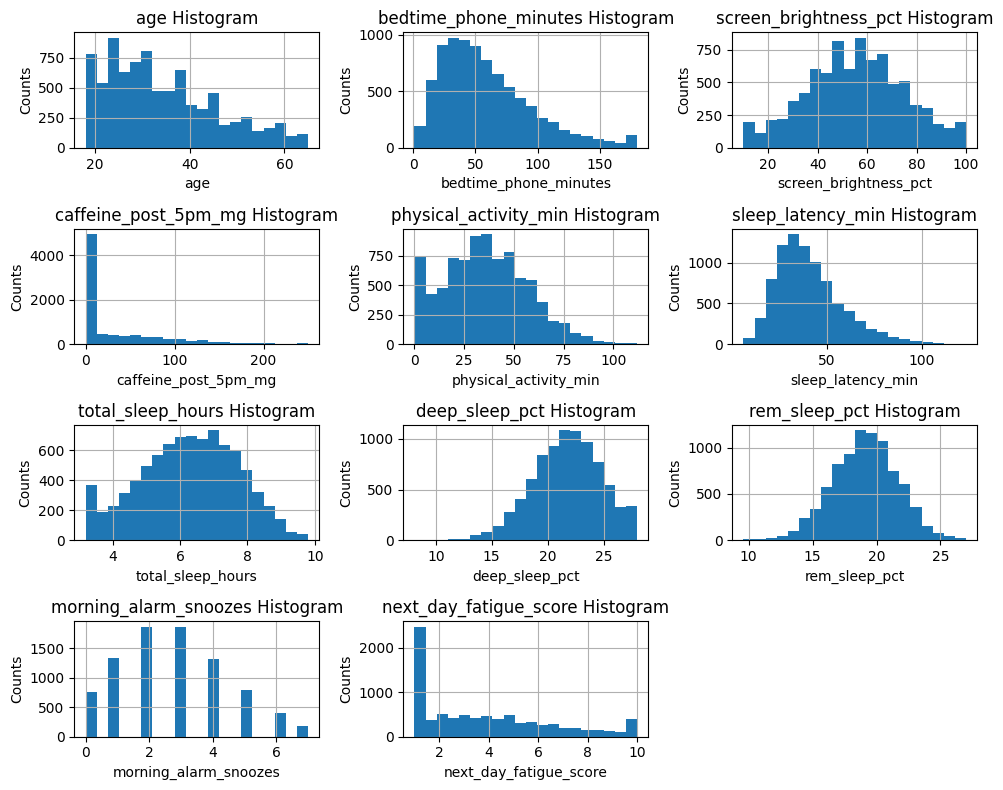

In [ ]:
columns = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
figure, axes = plt.subplots(4, 3, figsize=(10,8))

axes = axes.flatten()
for idx, col in enumerate(columns):
    df[col].hist(bins=20, ax=axes[idx])
    axes[idx].set_title(f'{col} Histogram')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Counts')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

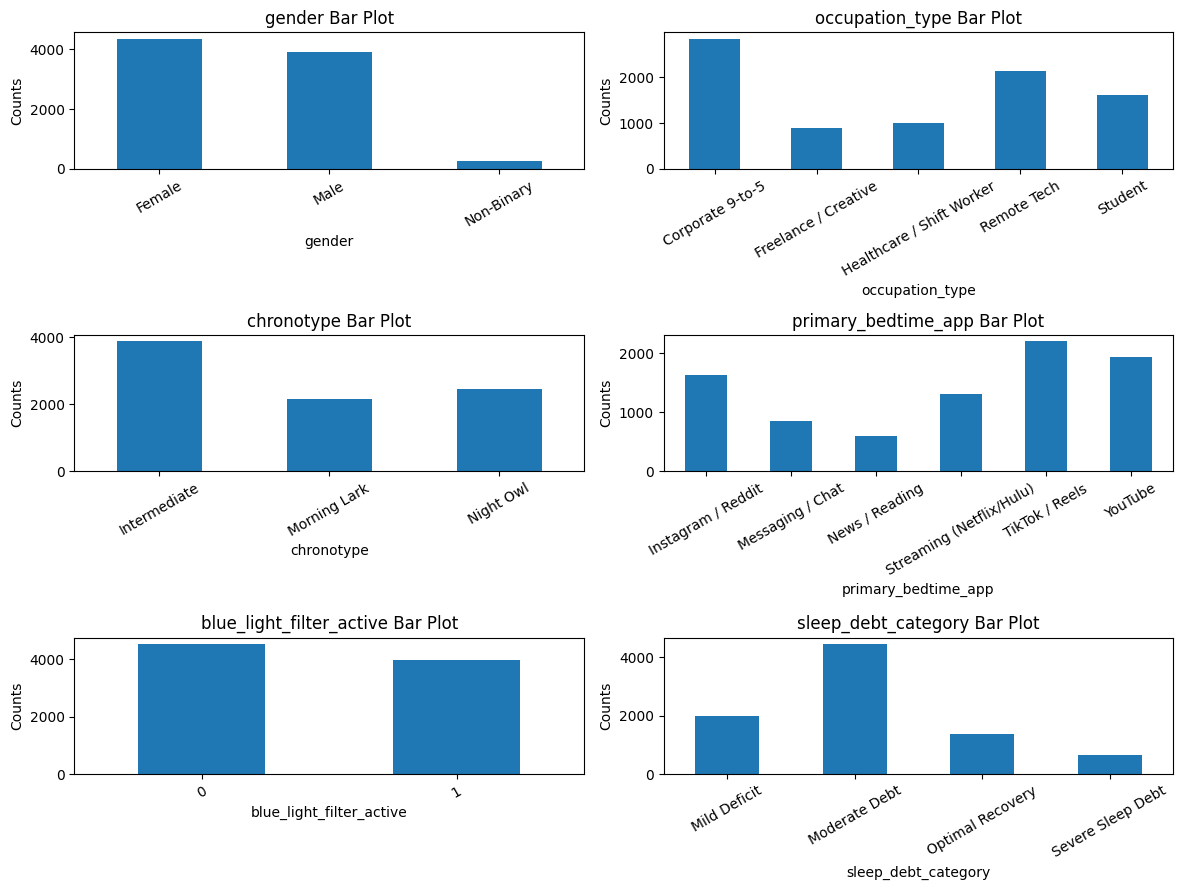

In [ ]:
columns = ['gender','occupation_type', 'chronotype', 'primary_bedtime_app', 'blue_light_filter_active','sleep_debt_category']
figure, axes = plt.subplots(3, 2, figsize=(12, 9))
axes = axes.flatten()

for idx, col in enumerate(columns):
    df[col].value_counts().sort_index().plot.bar(ax=axes[idx])
    axes[idx].tick_params(axis='x', rotation=30)
    axes[idx].set_title(f'{col} Bar Plot')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Counts')

plt.tight_layout()
plt.show()

### Class Imbalance

In [3]:
df['sleep_debt_category'].value_counts()
df['sleep_debt_category'].value_counts(normalize=True)

,proportion
sleep_debt_category,
Moderate Debt,0.524941
Mild Deficit,0.235765
Optimal Recovery,0.163176
Severe Sleep Debt,0.076118


The target variable presents a degree of class imbalance. In particular, the `Moderate Debt` class accounts for approximately 52.5% of the observations, whereas `Severe Sleep Debt` accounts for only 7.6%. So, the minority class is noticeably underrepresented.

## Task 2

In [4]:
df_part1 = df.drop(columns=['next_day_fatigue_score'])
df_part1

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,Severe Sleep Debt


## Task 3

### One-Hot Encoding

In [5]:
categorical_columns = [
    'gender',
    'occupation_type',
    'chronotype',
    'primary_bedtime_app',
    'blue_light_filter_active'
]

df_encoded = pd.get_dummies(
    df_part1,
    columns=categorical_columns,
    dtype=int
)
df_encoded

,user_id,age,bedtime_phone_minutes,screen_brightness_pct,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube,blue_light_filter_active_0,blue_light_filter_active_1
0,USR-00001,29,179,54,0,21,84.4,3.20,23.5,22.2,...,0,0,1,0,0,0,0,0,0,1
1,USR-00002,58,163,76,92,72,86.7,4.06,18.0,21.5,...,0,0,0,0,0,0,0,1,0,1
2,USR-00003,41,100,59,45,23,70.5,3.20,18.1,20.5,...,0,1,0,0,0,0,1,0,1,0
3,USR-00004,36,34,52,97,49,38.1,6.99,21.6,22.4,...,0,0,0,0,0,0,0,1,1,0
4,USR-00005,23,27,82,0,38,32.3,4.58,24.1,22.8,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,18,61,60,74,21.0,5.57,26.5,18.1,...,0,1,0,0,0,1,0,0,0,1
8496,USR-08497,64,138,58,0,58,84.3,3.99,20.4,19.4,...,0,1,0,0,0,0,1,0,0,1
8497,USR-08498,34,56,56,94,33,40.6,7.58,17.4,20.7,...,0,0,0,0,0,1,0,0,1,0
8498,USR-08499,23,165,72,0,52,123.3,3.20,14.2,15.8,...,0,1,0,0,0,0,1,0,1,0


## Task 4

### Convert DataFrame to Numpy arrays

In [6]:
input_df = df_encoded.drop(columns=['user_id', 'sleep_debt_category'])
target_df = df_encoded['sleep_debt_category']

x = input_df.to_numpy()
y = target_df.to_numpy()

x.shape, y.shape

((8500, 29), (8500,))

### Train, Validation and Test split

In [11]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, random_state=0, stratify=y)

x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size = 1/3, random_state=0, stratify=y_temp)

x_train.shape, y_train.shape, x_val.shape, y_val.shape, x_test.shape, y_test.shape

((5950, 29), (5950,), (1700, 29), (1700,), (850, 29), (850,))

## Task 5

### Normalization

In [8]:
columns = ['age', 'bedtime_phone_minutes','screen_brightness_pct','caffeine_post_5pm_mg','physical_activity_min',
 'sleep_latency_min',
 'total_sleep_hours',
 'deep_sleep_pct',
 'rem_sleep_pct',
 'morning_alarm_snoozes',]
idx = [input_df.columns.get_loc(c) for c in columns]

scaler = StandardScaler()
x_train[:, idx] = scaler.fit_transform(x_train[:, idx])
x_val[:, idx] = scaler.transform(x_val[:, idx])

In [9]:
def get_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_score': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'balanced_acc': balanced_accuracy_score(y_true, y_pred),
    }

N = len(x_train)
k_values = [3, 5, 15, 50, int(np.sqrt(N))+1]
weights = ['uniform', 'distance']

results = []
for w in weights:
  for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights = w, metric = 'euclidean')
    knn.fit(x_train, y_train)

    row = {'k': k, 'weights': w}
    for name, xs, ys in [('train', x_train, y_train), ('val', x_val, y_val)]:
        m = get_metrics(ys, knn.predict(xs))
        row.update({f'{name}_{key}': val for key, val in m.items()})
    results.append(row)

results_df = pd.DataFrame(results)
print(results_df.round(4))

    k   weights  train_accuracy  train_precision  train_recall  \
0   3   uniform          0.8798           0.8791        0.8507   
1   5   uniform          0.8587           0.8663        0.8125   
2  15   uniform          0.8413           0.8560        0.7752   
3  50   uniform          0.8296           0.8574        0.7357   
4  78   uniform          0.8234           0.8561        0.7207   
5   3  distance          1.0000           1.0000        1.0000   
6   5  distance          1.0000           1.0000        1.0000   
7  15  distance          1.0000           1.0000        1.0000   
8  50  distance          1.0000           1.0000        1.0000   
9  78  distance          1.0000           1.0000        1.0000   

   train_f1_score  train_balanced_acc  val_accuracy  val_precision  \
0          0.8636              0.8507        0.7688         0.7494   
1          0.8353              0.8125        0.7800         0.7807   
2          0.8069              0.7752        0.8100         0.8

The best combination, based on the validation F1 score, is `k=50` with weights=distance. With `weights=distance` the training score is `1.0` across all metrics, because every point is its own nearest neighbor. Therefore, the selection is based on the validation set. For small `k`, there is overtraining. For a large `k`, precision increases but recall drops. Accuracy is higher than recall and balanced accuracy, which implies that one of the classes is being identified less effectively.

## Task 6

In [10]:
x_train[:, idx] = scaler.inverse_transform(x_train[:, idx])
x_val[:, idx] = scaler.inverse_transform(x_val[:, idx])

x_full = np.concatenate([x_train, x_val])
y_full = np.concatenate([y_train, y_val])

scaler = StandardScaler()
x_full[:, idx] = scaler.fit_transform(x_full[:, idx])
x_test[:, idx] = scaler.transform(x_test[:, idx])

knn = KNeighborsClassifier(n_neighbors=50, weights='distance', metric='euclidean')
knn.fit(x_full, y_full)

final = pd.DataFrame({
    'Train+Val': get_metrics(y_full, knn.predict(x_full)),
    'Test': get_metrics(y_test, knn.predict(x_test)),
}).T
final.loc['Validation (q5)'] = [0.8188, 0.8376, 0.7324, 0.7716, 0.7324]
final = final.loc[['Train+Val', 'Validation (q5)', 'Test']]
print(final.round(4))

                 accuracy  precision  recall  f1_score  balanced_acc
Train+Val          1.0000     1.0000  1.0000    1.0000        1.0000
Validation (q5)    0.8188     0.8376  0.7324    0.7716        0.7324
Test               0.8094     0.8418  0.7264    0.7676        0.7264


`Train+Val` is `1.0` only because of distance weighting, so it isn't a real measure. `Validation` and `Test` are close, so the model generalizes to unseen data. The small drop on test is expected because k and weights were tuned on validation. Accuracy is higher than macro recall and balanced accuracy on both, so some class is recognized worse than the others.

## Task 7

In [12]:
x_cv = np.concatenate([x_train, x_val])
y_cv = np.concatenate([y_train, y_val])

scoring = {'accuracy': 'accuracy', 'precision': 'precision_macro', 'recall': 'recall_macro',
           'f1_score': 'f1_macro', 'balanced_acc': 'balanced_accuracy'}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

N = len(x_cv)
k_values = [3, 5, 15, 50, int(np.sqrt(N)) + 1]
weights = ['uniform', 'distance']

results, fold_scores = [], {}
for w in weights:
    for k in k_values:
        pipe = Pipeline([
            ('scale', ColumnTransformer([('num', StandardScaler(), idx)], remainder='passthrough')),
            ('knn', KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')),
        ])
        cv = cross_validate(pipe, x_cv, y_cv, cv=skf, scoring=scoring, return_train_score=True)
        row = {'k': k, 'weights': w}
        for m in scoring:
            row[f'train_{m}'] = cv[f'train_{m}'].mean()
            row[f'val_{m}'] = cv[f'test_{m}'].mean()
        results.append(row)
        fold_scores[(k, w)] = {m: cv[f'test_{m}'] for m in scoring}

cv_df = pd.DataFrame(results)
print(cv_df.round(4).to_string())

best = cv_df.loc[cv_df['val_f1_score'].idxmax()]
print('Best:', int(best['k']), best['weights'])

scores = fold_scores[(int(best['k']), best['weights'])]
ci_rows = []
for m, s in scores.items():
    mean, sem = s.mean(), stats.sem(s)
    low, high = stats.t.interval(0.95, df=len(s) - 1, loc=mean, scale=sem)
    ci_rows.append({'metric': m, 'mean': mean, 'ci_low': low, 'ci_high': high})
print(pd.DataFrame(ci_rows).round(4))

    k   weights  train_accuracy  val_accuracy  train_precision  val_precision  train_recall  val_recall  train_f1_score  val_f1_score  train_balanced_acc  val_balanced_acc
0   3   uniform          0.8818        0.7641           0.8787         0.7533        0.8454      0.7041          0.8602        0.7243              0.8454            0.7041
1   5   uniform          0.8611        0.7809           0.8656         0.7797        0.8126      0.7171          0.8350        0.7419              0.8126            0.7171
2  15   uniform          0.8393        0.8068           0.8521         0.8181        0.7723      0.7310          0.8035        0.7638              0.7723            0.7310
3  50   uniform          0.8271        0.8107           0.8539         0.8411        0.7339      0.7131          0.7760        0.7562              0.7339            0.7131
4  88   uniform          0.8161        0.8080           0.8504         0.8425        0.7083      0.6997          0.7546        0.7451       

5-fold stratified CV on the train part (train + validation) compared the 10 combinations, with the scaler fitted inside each fold and each metric averaged over the folds. The best combination by mean validation F1 was `k=15` with uniform weights. The top combinations (`k=15 uniform`, `k=15 distance`, `k=50 distance`) differ by less than 0.002 in F1, so they cannot really be told apart. Distance weighting gives train scores of `1.0` because each point is its own nearest neighbor, so selection used the validation folds only. The `95%` confidence intervals (t-distribution, 4 degrees of freedom) are fairly wide.

## Task 8

In [14]:
num_cols = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg',
            'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
            'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes']
num_idx = [input_df.columns.get_loc(c) for c in num_cols]

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

rows = []
for fold, (tr, te) in enumerate(outer_cv.split(x, y), 1):
    x_tr, x_te, y_tr, y_te = x[tr], x[te], y[tr], y[te]

    k_sqrt = int(np.sqrt(len(x_tr))) + 1
    pipe = Pipeline([
        ('scale', ColumnTransformer([('num', StandardScaler(), num_idx)], remainder='passthrough')),
        ('knn', KNeighborsClassifier(metric='euclidean')),
    ])
    grid = {'knn__n_neighbors': [3, 5, 15, 50, k_sqrt],
            'knn__weights': ['uniform', 'distance']}

    gs = GridSearchCV(pipe, grid, cv=inner_cv, scoring='f1_macro', n_jobs=-1)
    gs.fit(x_tr, y_tr)

    row = {'fold': fold,
           'best_k': gs.best_params_['knn__n_neighbors'],
           'best_weights': gs.best_params_['knn__weights'],
           'inner_f1': gs.best_score_}
    row.update(get_metrics(y_te, gs.predict(x_te)))
    rows.append(row)

nested_df = pd.DataFrame(rows)
print(nested_df.round(4).to_string())

metric_cols = ['accuracy', 'precision', 'recall', 'f1_score', 'balanced_acc']
print(nested_df[metric_cols].agg(['mean', 'std']).round(4))

   fold  best_k best_weights  inner_f1  accuracy  precision  recall  f1_score  balanced_acc
0     1      15      uniform    0.7739    0.8080     0.8199  0.7397    0.7710        0.7397
1     2      50     distance    0.7584    0.8083     0.8360  0.7066    0.7499        0.7066
2     3      15      uniform    0.7616    0.8087     0.8139  0.7331    0.7638        0.7331
      accuracy  precision  recall  f1_score  balanced_acc
mean    0.8084     0.8233  0.7265    0.7615        0.7265
std     0.0003     0.0114  0.0175    0.0107        0.0175


The best parameters were k=15 uniform in two folds and k=50 distance in one, so the top combinations are practically equivalent. The results agree with tasks 5 and 7, and nested CV is the least optimistic estimate since no outer data influenced parameter selection.

# Part 2

## Next Day Fatigue Score Histogram

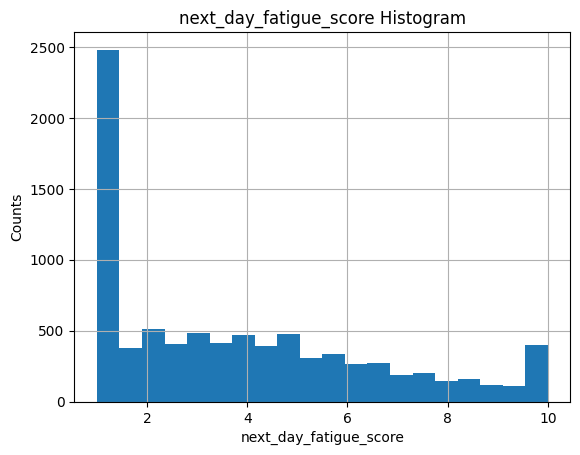

In [16]:
df['next_day_fatigue_score'].hist(bins=20)
plt.title('next_day_fatigue_score Histogram')
plt.xlabel('next_day_fatigue_score')
plt.ylabel('Counts')
plt.show()

## One-Hot Encoding and Numpy

In [17]:
df_part2 = df.drop(columns=['sleep_debt_category'])

categorical_columns = ['gender', 'occupation_type', 'chronotype',
                       'primary_bedtime_app', 'blue_light_filter_active']
df_encoded2 = pd.get_dummies(df_part2, columns=categorical_columns, dtype=int)

input_df2 = df_encoded2.drop(columns=['user_id', 'next_day_fatigue_score'])
x2 = input_df2.to_numpy(dtype=np.float64)
y2 = df_encoded2['next_day_fatigue_score'].to_numpy(dtype=np.float64)

x2.shape, y2.shape

((8500, 29), (8500,))

## Train, Validation and Test Split

In [18]:
x2_train, x2_temp, y2_train, y2_temp = train_test_split(x2, y2, test_size=0.3, random_state=0)
x2_val, x2_test, y2_val, y2_test = train_test_split(x2_temp, y2_temp, test_size=1/3, random_state=0)

x2_train.shape, x2_val.shape, x2_test.shape

((5950, 29), (1700, 29), (850, 29))

## Task 5

In [23]:
def get_reg_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

scaler = StandardScaler()
x2_train_s = x2_train.copy()
x2_val_s = x2_val.copy()
x2_train_s[:, num_idx] = scaler.fit_transform(x2_train[:, num_idx])
x2_val_s[:, num_idx] = scaler.transform(x2_val[:, num_idx])

N = len(x2_train_s)
k_values = [3, 5, 15, 50, int(np.sqrt(N)) + 1]
weights = ['uniform', 'distance']

results = []
for w in weights:
    for k in k_values:
        knn = KNeighborsRegressor(n_neighbors=k, weights=w, metric='euclidean')
        knn.fit(x2_train_s, y2_train)

        row = {'k': k, 'weights': w}
        for name, xs, ys in [('train', x2_train_s, y2_train), ('val', x2_val_s, y2_val)]:
            m = get_reg_metrics(ys, knn.predict(xs))
            row.update({f'{name}_{key}': v for key, v in m.items()})
        results.append(row)

results2_df = pd.DataFrame(results)
print(results2_df.round(4).to_string())

best2 = results2_df.loc[results2_df['val_RMSE'].idxmin()]

    k   weights  train_MAE  train_RMSE  train_R2  val_MAE  val_RMSE  val_R2
0   3   uniform     0.4849      0.6724    0.9368   0.6468    0.8934  0.8883
1   5   uniform     0.5085      0.6890    0.9337   0.5999    0.8164  0.9067
2  15   uniform     0.5407      0.7135    0.9289   0.5749    0.7677  0.9175
3  50   uniform     0.5852      0.7594    0.9194   0.5915    0.7701  0.9170
4  78   uniform     0.6060      0.7834    0.9143   0.6123    0.7938  0.9118
5   3  distance     0.0000      0.0000    1.0000   0.6456    0.8927  0.8885
6   5  distance     0.0000      0.0000    1.0000   0.5986    0.8153  0.9070
7  15  distance     0.0000      0.0000    1.0000   0.5722    0.7652  0.9181
8  50  distance     0.0000      0.0000    1.0000   0.5882    0.7664  0.9178
9  78  distance     0.0000      0.0000    1.0000   0.6079    0.7889  0.9129


The best combination by validation RMSE is `k=15` with distance weighting (MAE 0.572, RMSE 0.765, R² 0.918). Distance gives zero train error because each point is its own nearest neighbor, so selection used validation only. Small k overfits and large k underfits slightly.

## Task 6

In [24]:
x2_full = np.concatenate([x2_train, x2_val])
y2_full = np.concatenate([y2_train, y2_val])

scaler_full = StandardScaler()
x2_full_s = x2_full.copy()
x2_test_s = x2_test.copy()
x2_full_s[:, num_idx] = scaler_full.fit_transform(x2_full[:, num_idx])
x2_test_s[:, num_idx] = scaler_full.transform(x2_test[:, num_idx])

knn = KNeighborsRegressor(n_neighbors=int(best2['k']), weights=best2['weights'], metric='euclidean')
knn.fit(x2_full_s, y2_full)

final2 = pd.DataFrame({
    'Train+Val': get_reg_metrics(y2_full, knn.predict(x2_full_s)),
    'Test': get_reg_metrics(y2_test, knn.predict(x2_test_s)),
}).T
final2.loc['Validation (q5)'] = [best2['val_MAE'], best2['val_RMSE'], best2['val_R2']]
print(final2.loc[['Train+Val', 'Validation (q5)', 'Test']].round(4))

                    MAE    RMSE      R2
Train+Val        0.0000  0.0000  1.0000
Validation (q5)  0.5722  0.7652  0.9181
Test             0.5655  0.7598  0.9249


After merging train and validation and refitting the scaler, the test results are MAE 0.566, RMSE 0.760, R² 0.925, very close to validation. The model generalizes well, and the zero train error is only an effect of distance weighting.

## Task 7

In [25]:
x2_cv, y2_cv = x2_full, y2_full

scoring = {'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error',
           'R2': 'r2'}
sign = {'MAE': -1, 'RMSE': -1, 'R2': 1}
kf = KFold(n_splits=5, shuffle=True, random_state=0)

N = len(x2_cv)
k_values = [3, 5, 15, 50, int(np.sqrt(N)) + 1]

results, fold_scores = [], {}
for w in weights:
    for k in k_values:
        pipe = Pipeline([
            ('scale', ColumnTransformer([('num', StandardScaler(), num_idx)], remainder='passthrough')),
            ('knn', KNeighborsRegressor(n_neighbors=k, weights=w, metric='euclidean')),
        ])
        cv = cross_validate(pipe, x2_cv, y2_cv, cv=kf, scoring=scoring, return_train_score=True)
        row = {'k': k, 'weights': w}
        for m in scoring:
            row[f'train_{m}'] = sign[m] * cv[f'train_{m}'].mean()
            row[f'val_{m}'] = sign[m] * cv[f'test_{m}'].mean()
        results.append(row)
        fold_scores[(k, w)] = {m: sign[m] * cv[f'test_{m}'] for m in scoring}

cv2_df = pd.DataFrame(results)
print(cv2_df.round(4).to_string())

best_cv = cv2_df.loc[cv2_df['val_RMSE'].idxmin()]
print('Best:', int(best_cv['k']), best_cv['weights'])

scores = fold_scores[(int(best_cv['k']), best_cv['weights'])]
ci_rows = []
for m, s in scores.items():
    mean, sem = s.mean(), stats.sem(s)
    low, high = stats.t.interval(0.95, df=len(s) - 1, loc=mean, scale=sem)
    ci_rows.append({'metric': m, 'mean': mean, 'ci_low': low, 'ci_high': high})
print(pd.DataFrame(ci_rows).round(4))

    k   weights  train_MAE  val_MAE  train_RMSE  val_RMSE  train_R2  val_R2
0   3   uniform     0.4778   0.6512      0.6652    0.8956    0.9381  0.8878
1   5   uniform     0.5033   0.6113      0.6868    0.8251    0.9341  0.9048
2  15   uniform     0.5415   0.5786      0.7163    0.7659    0.9283  0.9179
3  50   uniform     0.5833   0.5959      0.7576    0.7736    0.9198  0.9163
4  88   uniform     0.6138   0.6220      0.7928    0.8029    0.9122  0.9098
5   3  distance     0.0000   0.6510      0.0000    0.8954    1.0000  0.8878
6   5  distance     0.0000   0.6102      0.0000    0.8243    1.0000  0.9050
7  15  distance     0.0000   0.5763      0.0000    0.7632    1.0000  0.9185
8  50  distance     0.0000   0.5926      0.0000    0.7696    1.0000  0.9171
9  88  distance     0.0000   0.6175      0.0000    0.7976    1.0000  0.9110
Best: 15 distance
  metric    mean  ci_low  ci_high
0    MAE  0.5763  0.5544   0.5982
1   RMSE  0.7632  0.7386   0.7879
2     R2  0.9185  0.9151   0.9220


5-fold CV also selects `k=15` with distance weighting (MAE 0.576, RMSE 0.763, R² 0.919). The 95% confidence intervals are narrow (e.g. RMSE 0.739 to 0.788), and the results agree with task 5 and 6.

## Task 8

In [26]:
num_cols = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'caffeine_post_5pm_mg',
            'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours',
            'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes']
num_idx = [input_df2.columns.get_loc(c) for c in num_cols]

outer_cv = KFold(n_splits=3, shuffle=True, random_state=0)
inner_cv = KFold(n_splits=5, shuffle=True, random_state=0)

rows = []
for fold, (tr, te) in enumerate(outer_cv.split(x2), 1):
    x_tr, x_te, y_tr, y_te = x2[tr], x2[te], y2[tr], y2[te]

    k_sqrt = int(np.sqrt(len(x_tr))) + 1
    pipe = Pipeline([
        ('scale', ColumnTransformer([('num', StandardScaler(), num_idx)], remainder='passthrough')),
        ('knn', KNeighborsRegressor(metric='euclidean')),
    ])
    grid = {'knn__n_neighbors': [3, 5, 15, 50, k_sqrt],
            'knn__weights': ['uniform', 'distance']}

    gs = GridSearchCV(pipe, grid, cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(x_tr, y_tr)

    row = {'fold': fold,
           'best_k': gs.best_params_['knn__n_neighbors'],
           'best_weights': gs.best_params_['knn__weights'],
           'inner_RMSE': -gs.best_score_}
    row.update(get_reg_metrics(y_te, gs.predict(x_te)))
    rows.append(row)

nested2_df = pd.DataFrame(rows)
print(nested2_df.round(4).to_string())
print(nested2_df[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(4))

   fold  best_k best_weights  inner_RMSE     MAE    RMSE      R2
0     1      15     distance      0.7734  0.5729  0.7666  0.9195
1     2      15     distance      0.7706  0.5756  0.7636  0.9192
2     3      15     distance      0.7750  0.5827  0.7601  0.9187
         MAE    RMSE      R2
mean  0.5771  0.7634  0.9191
std   0.0050  0.0032  0.0004


Nested CV selected `k=15` with distance weighting in all three outer folds, with mean MAE 0.577, RMSE 0.763 and R² 0.919 (very small std). This matches task 7 and shows no optimistic bias, so about 92% of the variance of next-day fatigue is explained.